## Data and Sentiment Analysis

**Load the current US–NYT experiment dataset** 

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd

PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'modelling').exists())
sys.path.insert(0, str(PROJECT_ROOT))

from modelling.sentiment import add_sentiment_lags, current_method_catalog

DATA_DIR = PROJECT_ROOT / 'data/processed/modelling_datasets/extended_2025'
data = pd.read_csv(DATA_DIR / 'us_nyt_monthly_experiment.csv', parse_dates=['Date'])
metadata = json.loads((DATA_DIR / 'us_nyt_monthly_experiment_metadata.json').read_text(encoding='utf-8'))

In [2]:
coverage = pd.DataFrame({
    'item': ['Region', 'News source', 'First month', 'Last month', 'Monthly rows', 'Articles'],
    'value': [
        metadata['region_code'],
        metadata['news_source']['source_code'],
        data['Date'].min().date(),
        data['Date'].max().date(),
        len(data),
        metadata['coverage']['article_count_total'],
    ],
})
display(coverage)
display(data.head())

,item,value
0,Region,US
1,News source,NYT
2,First month,2007-01-01
3,Last month,2025-12-01
4,Monthly rows,228
5,Articles,18063


,Date,Experiment_News_Source,CPIAUCSL,UNRATE,FEDFUNDS,INDPRO,MCOILWTICO,News_Source,News_Sentiment,Sentiment_Median,Sentiment_Std,Negative_Share,Neutral_Share,Positive_Share,Article_Count,Inflation_MoM,Inflation_YoY,Unemployment_Change,Fed_Funds_Change,IP_Growth_MoM,Oil_Price_Growth,Inflation_Lag1,News_Sentiment_Lag1,Unemployment_Change_Lag1,Fed_Funds_Change_Lag1,IP_Growth_MoM_Lag1,Oil_Price_Growth_Lag1
0,2007-01-01,NYT,203.437,4.6,5.25,99.8346,54.51,NYT,-0.329116,-0.522036,0.591161,0.578947,0.263157,0.157894,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2007-02-01,NYT,204.226,4.5,5.26,100.7753,59.28,NYT,-0.170357,-0.053693,0.650998,0.450000,0.300000,0.250000,40,0.387835,NaN,-0.1,0.01,0.942258,8.388781,NaN,-0.329116,NaN,NaN,NaN,NaN
2,2007-03-01,NYT,205.288,4.4,5.26,100.9547,60.44,NYT,-0.404710,-0.572544,0.544493,0.568627,0.294117,0.137254,51,0.520012,NaN,-0.1,0.00,0.178020,1.937916,0.387835,-0.170357,-0.1,0.01,0.942258,8.388781
3,2007-04-01,NYT,205.904,4.5,5.25,101.6334,63.98,NYT,-0.275370,-0.290138,0.506662,0.466666,0.333333,0.200000,30,0.300066,NaN,0.1,-0.01,0.672282,5.691940,0.520012,-0.404710,-0.1,0.00,0.178020,1.937916
4,2007-05-01,NYT,206.755,4.4,5.25,101.7306,63.46,NYT,-0.172399,-0.199209,0.613092,0.457142,0.314285,0.228571,35,0.413299,NaN,-0.1,0.00,0.095638,-0.816075,0.300066,-0.275370,0.1,-0.01,0.672282,5.691940


**Current sentiment method**

In [3]:
data, sentiment_features = add_sentiment_lags(data, lags=6)
display(pd.DataFrame(current_method_catalog()))
print('Existing forecasting features:', sentiment_features)

Existing forecasting features: ['Sentiment_Lag1', 'Sentiment_Lag2', 'Sentiment_Lag3', 'Sentiment_Lag4', 'Sentiment_Lag5', 'Sentiment_Lag6']


,method,level,monthly_primary_feature,forecast_features,status,notes
0,generic_finbert,article,News_Sentiment,"[Sentiment_Lag1, Sentiment_Lag2, Sentiment_Lag...",implemented,Generic financial sentiment; not yet manually ...
1,alternative_finbert_aggregations,month,News_Sentiment,"[News_Sentiment, Sentiment_Median, Negative_Sh...",implemented,"Mean, median, negative share, and dispersion f..."


In [4]:
sentiment_columns = [
    'News_Sentiment', 'Negative_Share', 'Neutral_Share',
    'Positive_Share', 'Article_Count',
]
display(data[sentiment_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
News_Sentiment,228.0,-0.302961,0.093622,-0.602114,-0.358378,-0.308840,-0.248705,0.075952
Negative_Share,228.0,0.488768,0.085013,0.117647,0.438142,0.487936,0.538801,0.711340
Neutral_Share,228.0,0.373343,0.083603,0.177778,0.314682,0.373214,0.429226,0.617647
Positive_Share,228.0,0.137887,0.051892,0.030927,0.098360,0.133831,0.172579,0.315789
Article_Count,228.0,79.223684,39.166289,25.000000,51.000000,72.000000,95.500000,222.000000


Out[5]: <Axes: title={'center': 'Current monthly generic FinBERT sentiment'}, xlabel='Date', ylabel='Mean sentiment score'>


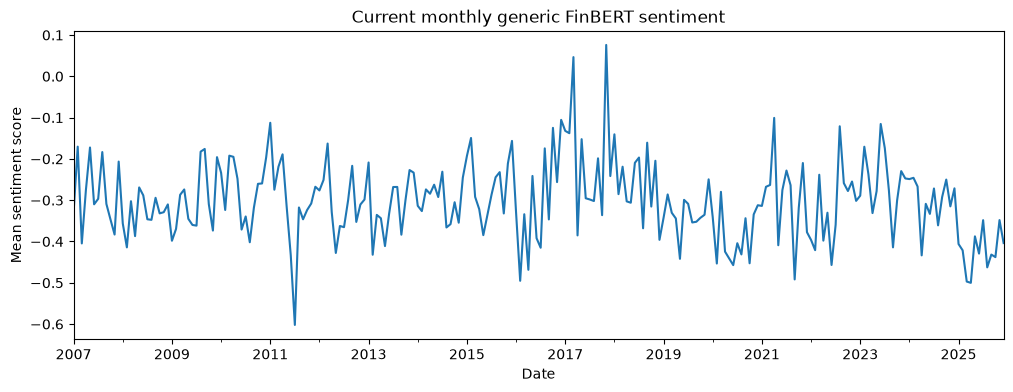

In [5]:
data.set_index('Date')['News_Sentiment'].plot(
    figsize=(12, 4),
    title='Current monthly generic FinBERT sentiment',
    ylabel='Mean sentiment score',
)